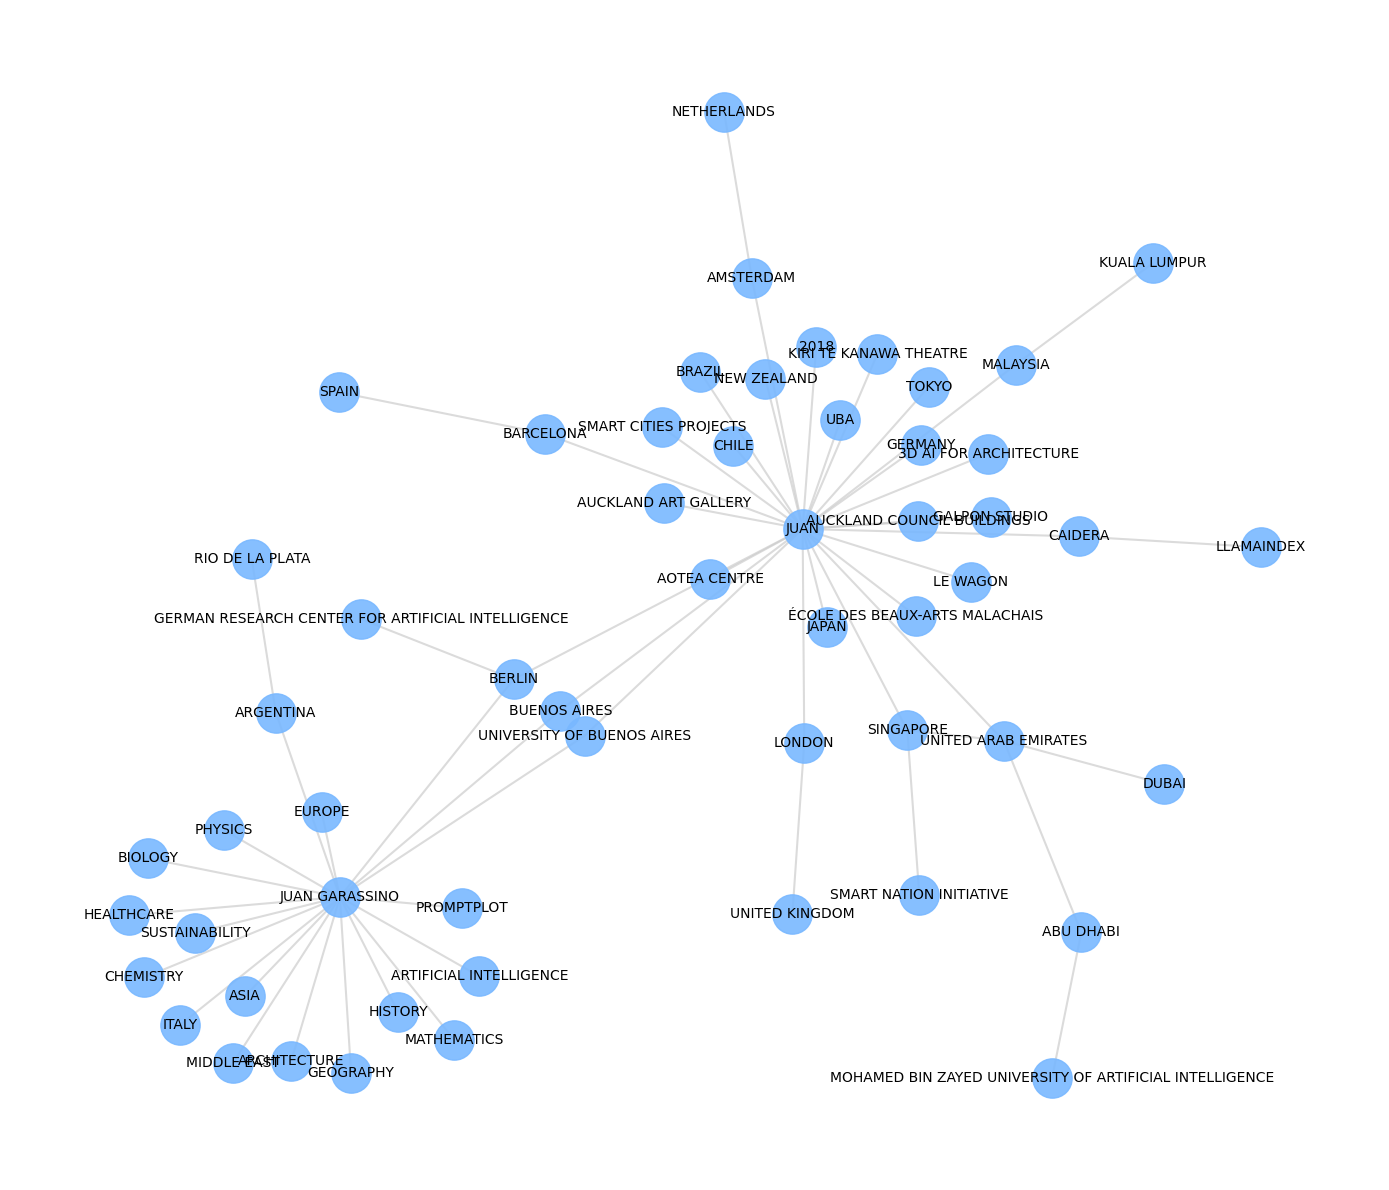

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

# Load the graph
G = nx.read_graphml("graph.graphml")

# Choose a layout — spring works well for most graphs
pos = nx.spring_layout(G, seed=42, k=0.3)

# Set up the figure
plt.figure(figsize=(14, 12))
plt.axis('off')

# Draw nodes
nx.draw_networkx_nodes(
    G, pos,
    node_color="#79b8ff",
    node_size=800,
    alpha=0.9
)

# Draw edges
nx.draw_networkx_edges(
    G, pos,
    edge_color="#cccccc",
    width=1.5,
    alpha=0.7
)

# Draw labels
nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_family="sans-serif"
)

plt.tight_layout()
plt.show()


In [5]:
import networkx as nx
import matplotlib.pyplot as plt

# Load the graph
G = nx.read_graphml("graph.graphml")

# Use a spring layout with more spacing between nodes
pos = nx.spring_layout(G, seed=42, k=0.7)

# Set matplotlib style
plt.style.use("seaborn-white")

# Create figure
plt.figure(figsize=(16, 14))
plt.axis('off')

# Draw shadow behind nodes for depth
shadow_pos = {node: (x+0.005, y-0.005) for node, (x, y) in pos.items()}
nx.draw_networkx_nodes(
    G, shadow_pos,
    node_color="#aaaaaa",
    node_size=900,
    alpha=0.2
)

# Draw main nodes
nx.draw_networkx_nodes(
    G, pos,
    node_color="#4fa3d1",
    edgecolors="#003f5c",
    linewidths=1,
    node_size=900,
    alpha=0.95
)

# Draw edges
nx.draw_networkx_edges(
    G, pos,
    edge_color="#bbbbbb",
    width=1.5,
    alpha=0.6
)

# Draw labels with padding
nx.draw_networkx_labels(
    G, pos,
    font_size=10,
    font_family="DejaVu Sans",
    font_weight="bold",
    verticalalignment="center",
    horizontalalignment="center",
    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.2", alpha=0.8)
)

plt.tight_layout()
plt.show()


OSError: 'seaborn-white' is not a valid package style, path of style file, URL of style file, or library style name (library styles are listed in `style.available`)

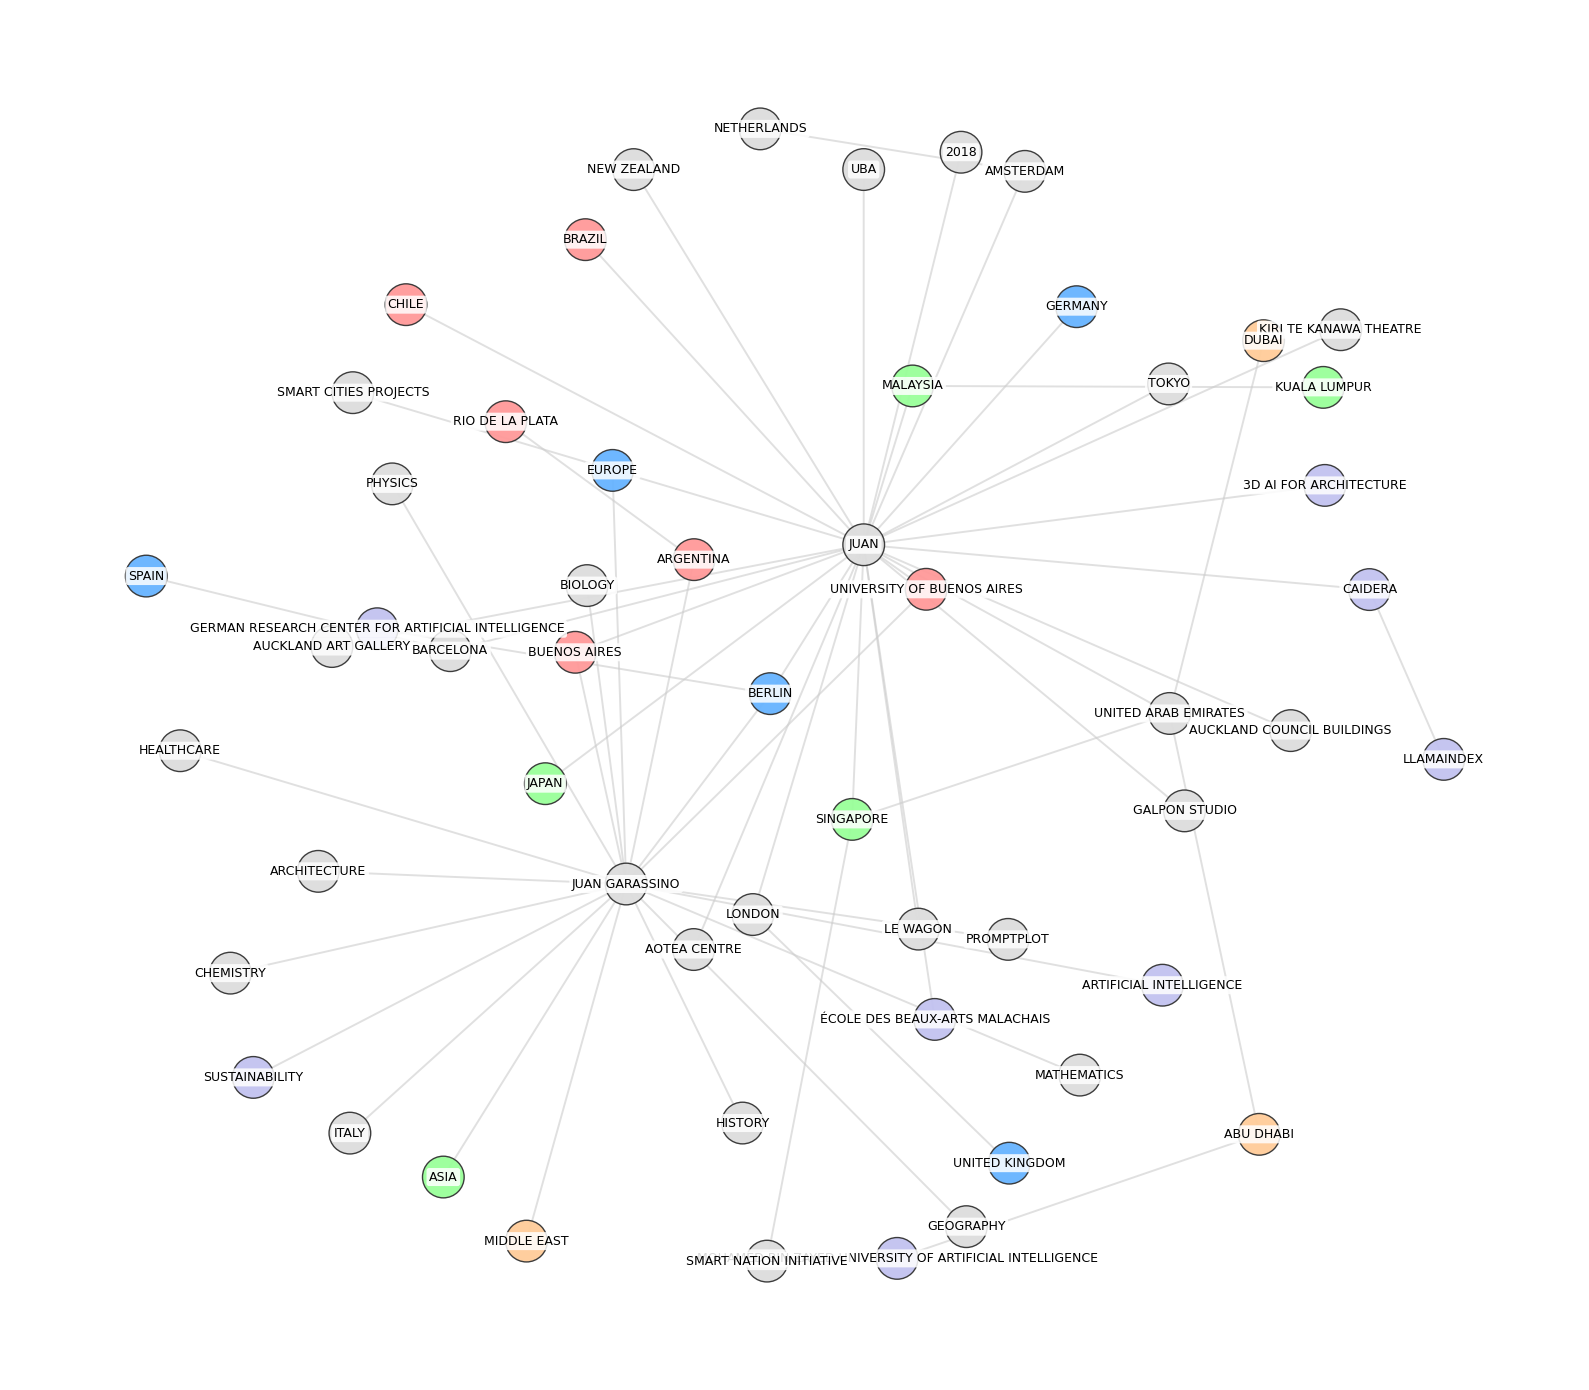

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict

# --- Configuration ---
GRAPHML_PATH = "graph.graphml"
EXPORT_PNG = "graph_high_res.png"
EXPORT_SVG = "graph_high_res.svg"
FIGSIZE = (16, 14)
DPI = 300

# --- Heuristic categorization ---
def categorize_node(node_label: str) -> str:
    label = node_label.upper()
    if any(kw in label for kw in ["ARGENTINA", "BRAZIL", "CHILE", "RIO", "BUENOS AIRES"]):
        return "South America"
    elif any(kw in label for kw in ["GERMANY", "UK", "UNITED KINGDOM", "FRANCE", "SPAIN", "EUROPE", "BERLIN"]):
        return "Europe"
    elif any(kw in label for kw in ["JAPAN", "ASIA", "KUALA LUMPUR", "SINGAPORE", "MALAYSIA"]):
        return "Asia"
    elif any(kw in label for kw in ["ABU DHABI", "DUBAI", "MIDDLE EAST"]):
        return "Middle East"
    elif any(kw in label for kw in ["AI", "INTELLIGENCE", "LLAMAINDEX"]):
        return "Technology"
    else:
        return "Other"

CATEGORY_COLORS = {
    "South America": "#ff9999",
    "Europe": "#66b3ff",
    "Asia": "#99ff99",
    "Middle East": "#ffcc99",
    "Technology": "#c2c2f0",
    "Other": "#dddddd"
}

# --- Load and process graph ---
G = nx.read_graphml(GRAPHML_PATH)
categories = {node: categorize_node(node) for node in G.nodes()}
colors = [CATEGORY_COLORS[categories[node]] for node in G.nodes()]
layout = nx.spring_layout(G, seed=42, k=0.7)

# --- Draw plot ---
plt.figure(figsize=FIGSIZE)
plt.axis("off")

# Edges
nx.draw_networkx_edges(G, layout, edge_color="#cccccc", width=1.4, alpha=0.6)

# Nodes
nx.draw_networkx_nodes(
    G, layout,
    node_color=colors,
    node_size=900,
    edgecolors="#333333",
    linewidths=1.0,
    alpha=0.95
)

# Labels
nx.draw_networkx_labels(
    G, layout,
    font_size=9,
    font_family="DejaVu Sans",
    bbox=dict(facecolor="white", edgecolor="none", boxstyle="round,pad=0.2", alpha=0.85)
)

# --- Export ---
plt.tight_layout()
plt.savefig(EXPORT_PNG, dpi=DPI, bbox_inches="tight")
plt.savefig(EXPORT_SVG, format="svg", bbox_inches="tight")
plt.show()
